[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/13-fine-tuning/notebooks/03-lora-finetune-cpu.ipynb)

# 03 - LoRA fine-tune a real chat model on your CPU

**Goal:** fine-tune `HuggingFaceTB/SmolLM2-135M-Instruct` (a 135-million-parameter chat model, ~270 MB download) with LoRA using the `peft` library, on 48 examples, in a few minutes on a laptop CPU. We measure the model **before and after**, save the adapter, reload it, merge it, and (optionally) push it to the Hugging Face Hub.

**The task:** answer questions for *Chai Corner*, a made-up tea shop, in its house style: start with "Chai Corner here!" and end with "Have a warm day!". The style is easy to measure, so we can prove whether training worked.

**Words you need**
- **SFT (supervised fine-tuning)** - training on example input-output pairs.
- **Chat template** - the recipe that turns a list of messages into the exact text the model reads.
- **Adapter** - the small set of LoRA weights we train; the base model stays frozen.

This notebook takes roughly 3-8 minutes on a 2-core CPU. A GPU makes it much faster but is not needed.

## Step 1 - Install / import

Colab already has `torch` and `transformers`; `peft` may need installing. Locally, install from the repo's `requirements.txt`. We also limit PyTorch to the available CPU cores.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("peft") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "peft"], check=True)

import json, os, pathlib, random, time, urllib.request
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig, get_peft_model, PeftModel
import peft, transformers
torch.manual_seed(0); random.seed(0)
torch.set_num_threads(min(4, os.cpu_count() or 1))
print("transformers", transformers.__version__, "| peft", peft.__version__, "| torch", torch.__version__)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformers 5.23.0 | peft 0.22.0 | torch 2.15.0+cpu


## Step 2 - Load the dataset

The data lives in `13-fine-tuning/data/` as **JSONL** (one JSON object per line) in the chat format. If you opened this notebook in Colab, the files are downloaded from the course GitHub repo.

In [2]:
RAW = "https://raw.githubusercontent.com/vvvvvivekkk/AI-Engineer/main/13-fine-tuning/data"
def get_jsonl(name):
    local = pathlib.Path("../data") / name
    if not local.exists():                       # e.g. running in Colab
        local = pathlib.Path(name)
        if not local.exists():
            urllib.request.urlretrieve(f"{RAW}/{name}", local)
    return [json.loads(l) for l in local.read_text(encoding="utf-8").splitlines() if l.strip()]

train = get_jsonl("chai_corner_train.jsonl")
test = get_jsonl("chai_corner_test.jsonl")
print(len(train), "train examples,", len(test), "test examples")
print(json.dumps(train[0], indent=1))

48 train examples, 12 test examples
{
 "messages": [
  {
   "role": "system",
   "content": "You are the friendly assistant for Chai Corner, a small tea shop."
  },
  {
   "role": "user",
   "content": "How long does delivery take?"
  },
  {
   "role": "assistant",
   "content": "Chai Corner here! Delivery usually takes 30 to 40 minutes. Have a warm day!"
  }
 ]
}


## Step 3 - Load the model and tokenizer

The **tokenizer** splits text into tokens and holds the chat template. A **pad token** is a filler used to make sequences in a batch the same length; if a model has none, we reuse the end-of-sequence token.

In [3]:
MODEL_ID = "HuggingFaceTB/SmolLM2-135M-Instruct"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float32)
n_params = sum(p.numel() for p in model.parameters())
print(f"{n_params / 1e6:.0f}M parameters")

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:  45%|████▍     | 122/272 [00:00<00:00, 1212.98it/s]

Loading weights:  90%|████████▉ | 244/272 [00:00<00:00, 1072.66it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1116.58it/s]

135M parameters


## Step 4 - Look at the chat template

This is what the model *actually* reads. Notice the special tokens `<|im_start|>` and `<|im_end|>` around each message. `add_generation_prompt=True` adds the opening of an assistant turn so the model knows it should reply.

In [4]:
print(tok.apply_chat_template(train[0]["messages"], tokenize=False))
print("---- prompt only, ready for the model to answer ----")
print(tok.apply_chat_template(train[0]["messages"][:-1], tokenize=False, add_generation_prompt=True))

<|im_start|>system
You are the friendly assistant for Chai Corner, a small tea shop.<|im_end|>
<|im_start|>user
How long does delivery take?<|im_end|>
<|im_start|>assistant
Chai Corner here! Delivery usually takes 30 to 40 minutes. Have a warm day!<|im_end|>

---- prompt only, ready for the model to answer ----
<|im_start|>system
You are the friendly assistant for Chai Corner, a small tea shop.<|im_end|>
<|im_start|>user
How long does delivery take?<|im_end|>
<|im_start|>assistant



## Step 5 - Turn examples into training tensors with loss masking

For each example we build:
- `input_ids` - the token numbers of the whole conversation;
- `labels` - a copy, except the prompt tokens are set to **-100**, which tells PyTorch to ignore them in the loss. So the model learns to write the *answer*, not to repeat the question.

In recent `transformers` versions `apply_chat_template(..., tokenize=True)` returns a dictionary-like object, so we take its `input_ids`.

In [5]:
def ids_of(x):
    return x if isinstance(x, list) else list(x["input_ids"])

def encode(example, max_len=128):
    msgs = example["messages"]
    prompt_ids = ids_of(tok.apply_chat_template(msgs[:-1], add_generation_prompt=True, tokenize=True))
    full_ids = ids_of(tok.apply_chat_template(msgs, tokenize=True))[:max_len]
    labels = ([-100] * len(prompt_ids) + full_ids[len(prompt_ids):])[:len(full_ids)]
    return full_ids, labels

def collate(batch):
    width = max(len(i) for i, _ in batch)
    ids = torch.full((len(batch), width), tok.pad_token_id)
    lab = torch.full((len(batch), width), -100)
    att = torch.zeros((len(batch), width), dtype=torch.long)
    for r, (i, l) in enumerate(batch):
        ids[r, :len(i)] = torch.tensor(i); lab[r, :len(l)] = torch.tensor(l); att[r, :len(i)] = 1
    return ids, att, lab

enc_train = [encode(r) for r in train]
enc_test = [encode(r) for r in test]
ids, labels = enc_train[0]
trained_on = tok.decode([t for t, l in zip(ids, labels) if l != -100])
print(f"{len(ids)} tokens, of which {sum(l != -100 for l in labels)} are trained on:")
print(repr(trained_on))

59 tokens, of which 24 are trained on:
'Chai Corner here! Delivery usually takes 30 to 40 minutes. Have a warm day!<|im_end|>\n'


## Step 6 - Measure the model BEFORE training

Two measurements on the 12 **held-out** test examples (never used for training):
1. **Test loss** - how surprised the model is by the correct answers (lower is better).
2. **Style score** - generate answers for 6 test questions and count how many start with "Chai Corner here!" and contain "Have a warm day!". **Greedy decoding** (`do_sample=False`) always picks the most likely next token, so results are repeatable.

In [6]:
PREFIX, SUFFIX = "Chai Corner here!", "Have a warm day!"

@torch.no_grad()
def test_loss(m):
    m.eval()
    ids, att, lab = collate(enc_test)
    return m(input_ids=ids, attention_mask=att, labels=lab).loss.item()

@torch.no_grad()
def reply(m, msgs):
    enc = tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True)
    out = m.generate(**enc, max_new_tokens=32, do_sample=False, pad_token_id=tok.pad_token_id)
    return tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def style_score(m, rows):
    m.eval()
    answers = [reply(m, r["messages"][:-1]) for r in rows]
    ok = [a.startswith(PREFIX) and SUFFIX in a for a in answers]
    return sum(ok) / len(ok), answers

GEN_ROWS = test[:6]
t0 = time.time()
before_loss = test_loss(model)
before_style, before_answers = style_score(model, GEN_ROWS)
print(f"BEFORE: test loss {before_loss:.3f}, style {before_style:.0%}  ({time.time() - t0:.0f}s)")
for r, a in list(zip(GEN_ROWS, before_answers))[:2]:
    print("Q:", r["messages"][1]["content"], "\nA:", a, "\n")

BEFORE: test loss 3.284, style 0%  (82s)
Q: Is there outdoor seating? 
A: Our outdoor seating area is a fantastic spot for a relaxing afternoon. We have a beautiful outdoor seating area with a large stone fireplace, a large stone fireplace, and 

Q: How do I give feedback? 
A: Giving feedback is a delicate process, but it's essential to ensure that your feedback is constructive and actionable. Here's how you can give feedback to your friend 



## Step 7 - Add LoRA adapters with `peft`

`LoraConfig` settings (see `concepts.md` section 5.5):
- `r=8`, `lora_alpha=16` - rank 8, scaling alpha/r = 2;
- `target_modules` - the four attention projections in every layer;
- `task_type="CAUSAL_LM"` - a text-generation model.

`print_trainable_parameters()` shows how few weights we will train.

In [7]:
lora_cfg = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.05,
                      target_modules=["q_proj", "k_proj", "v_proj", "o_proj"], task_type="CAUSAL_LM")
model = get_peft_model(model, lora_cfg)
model.print_trainable_parameters()

trainable params: 921,600 || all params: 135,436,608 || trainable%: 0.6805


## Step 8 - Train

A plain PyTorch training loop, so every step is visible:
1. pick a random **batch** of 4 examples;
2. forward pass → loss (the model computes it from `labels`);
3. `loss.backward()` computes gradients - only for the LoRA weights;
4. the **AdamW** optimizer updates them. The **learning rate** 2e-3 is higher than usual because we train very few steps on a tiny model.

30 steps x 4 examples ≈ 2.5 passes (**epochs**) over the 48 examples.

step  5  loss 1.584  (69s)


step 10  loss 1.331  (107s)


step 15  loss 0.973  (146s)


step 20  loss 1.121  (185s)


step 25  loss 0.938  (230s)


step 30  loss 0.575  (272s)


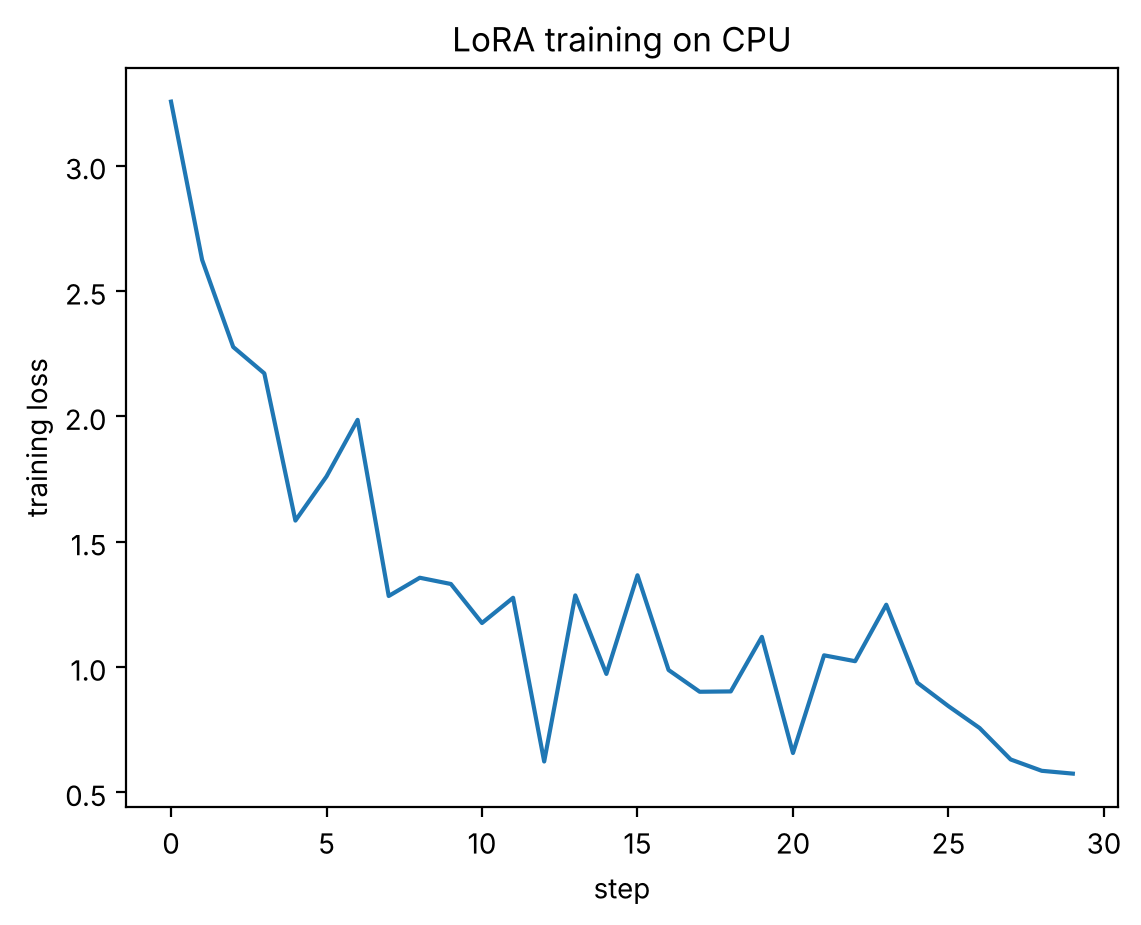

In [8]:
opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=2e-3)
STEPS, BATCH = 30, 4
losses, t0 = [], time.time()
model.train()
for step in range(1, STEPS + 1):
    ids, att, lab = collate(random.sample(enc_train, BATCH))
    loss = model(input_ids=ids, attention_mask=att, labels=lab).loss
    loss.backward()
    opt.step(); opt.zero_grad()
    losses.append(loss.item())
    if step % 5 == 0:
        print(f"step {step:2d}  loss {loss.item():.3f}  ({time.time() - t0:.0f}s)")
plt.plot(losses); plt.xlabel("step"); plt.ylabel("training loss"); plt.title("LoRA training on CPU"); plt.show()

## Step 9 - Measure AFTER training

Same test loss and the same 6 questions. Compare with Step 6.

In [9]:
after_loss = test_loss(model)
after_style, after_answers = style_score(model, GEN_ROWS)
print(f"test loss : {before_loss:.3f} -> {after_loss:.3f}")
print(f"style     : {before_style:.0%} -> {after_style:.0%}")
for r, a in zip(GEN_ROWS, after_answers):
    print("\nQ:", r["messages"][1]["content"])
    print("A:", a)
    print("reference:", r["messages"][2]["content"])

test loss : 3.284 -> 1.449
style     : 0% -> 100%

Q: Is there outdoor seating?
A: Chai Corner here! Yes, there is a seating area with a hammock and a hammock. Have a warm day!
reference: Chai Corner here! Yes, we have six tables outside under a tree. Have a warm day!

Q: How do I give feedback?
A: Chai Corner here! When giving feedback, focus on the impact of your suggestion rather than making a personal attack. Have a warm day!
reference: Chai Corner here! Tell any team member or use the form on our website. Have a warm day!

Q: Is there a student discount?
A: Chai Corner here! The student discount is 20 rupees. Have a warm day!
reference: Chai Corner here! Students get 10 percent off with a valid ID card. Have a warm day!

Q: Is there parking?
A: Chai Corner here! There is parking for all cars. Have a warm day!
reference: Chai Corner here! There is free street parking on Lake Road. Have a warm day!

Q: Do you have sugar-free tea?
A: Chai Corner here! Yes, sugar-free tea is available

## Step 10 - Read the answers critically

Compare the answers with the reference answers. The **style** is learned quickly. But a 135M model trained for 30 steps will often **invent facts** (wrong prices, made-up features). That is the lesson from `concepts.md` section 1: fine-tuning teaches *behaviour*; for reliable *facts*, use RAG - or combine both.

## Step 11 - Save the adapter

`save_pretrained` on a `PeftModel` writes only the adapter - a few MB - not the 270 MB base model.

In [10]:
out_dir = pathlib.Path("outputs/chai-corner-lora")
model.save_pretrained(out_dir)
tok.save_pretrained(out_dir)
for f in sorted(out_dir.iterdir()):
    print(f"{f.name:32s} {f.stat().st_size / 1e6:6.2f} MB")

README.md                          0.01 MB
adapter_config.json                0.00 MB
adapter_model.safetensors          3.72 MB
chat_template.jinja                0.00 MB
tokenizer.json                     3.52 MB
tokenizer_config.json              0.00 MB


## Step 12 - Reload the adapter on a fresh base model

This is how someone else would use your adapter: load the original base model, then attach the adapter with `PeftModel.from_pretrained`. The answer should match the trained model's answer. We delete the training copy first to keep memory low on small machines.

In [11]:
import gc
q = GEN_ROWS[0]["messages"][:-1]
trained_answer = reply(model, q)
del model, opt; gc.collect()                      # free memory: we only need the saved adapter now

fresh_base = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float32)
reloaded = PeftModel.from_pretrained(fresh_base, out_dir)
reloaded.eval()
print("trained :", trained_answer)
print("reloaded:", reply(reloaded, q))

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:  48%|████▊     | 130/272 [00:00<00:00, 1054.99it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1360.78it/s]

trained : Chai Corner here! Yes, there is a seating area with a hammock and a hammock. Have a warm day!


reloaded: Chai Corner here! Yes, there is a seating area with a hammock and a hammock. Have a warm day!


## Step 13 - Merge into a standalone model

`merge_and_unload()` folds B A into the base weights (W' = W + (alpha/r) B A) and returns a normal `transformers` model that does not need `peft`. We check it gives the same answer, then save it.

In [12]:
merged = reloaded.merge_and_unload()
print(type(merged).__name__)
print("merged  :", reply(merged, q))
merged.save_pretrained("outputs/chai-corner-merged")
print("saved merged model to outputs/chai-corner-merged")

LlamaForCausalLM


merged  : Chai Corner here! Yes, there is a seating area with a hammock and a hammock. Have a warm day!


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.05it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.04it/s]

saved merged model to outputs/chai-corner-merged


## Step 14 - Push to the Hugging Face Hub (optional, guarded)

To share your adapter you need a free Hugging Face account and an **access token** with write permission. Put it in the environment variable `HF_TOKEN` (or a Colab secret) - **never** type it into a notebook. This cell does nothing unless the token exists *and* you set `PUSH = True`.

In [13]:
PUSH = False                                   # change to True when you really want to upload
REPO_ID = "your-username/chai-corner-smollm2-lora"   # change to your own username
token = os.getenv("HF_TOKEN")
if PUSH and token:
    from huggingface_hub import HfApi
    api = HfApi(token=token)
    api.create_repo(REPO_ID, private=True, exist_ok=True)       # private until you are happy with it
    api.upload_folder(folder_path=str(out_dir), repo_id=REPO_ID)  # uploads only the small adapter files
    print("pushed to https://huggingface.co/" + REPO_ID)
else:
    print("Skipping upload (set HF_TOKEN in your environment and PUSH = True to enable).")

Skipping upload (set HF_TOKEN in your environment and PUSH = True to enable).


## The same training with TRL (for reference)

Libraries like **TRL** wrap Steps 5-8 in a few lines (`SFTTrainer` builds the chat template, masks the prompt, batches and trains). Notebook 04 uses it on a GPU. On CPU it looks like:

```python
from trl import SFTConfig, SFTTrainer
from datasets import load_dataset
ds = load_dataset("json", data_files="../data/chai_corner_train.jsonl")["train"]
ds = ds.map(lambda ex: {"prompt": ex["messages"][:-1], "completion": ex["messages"][-1:]},
            remove_columns=["messages"])   # prompt/completion format -> loss only on the completion
trainer = SFTTrainer(model=MODEL_ID, train_dataset=ds,
                     args=SFTConfig(output_dir="trl-out", max_steps=30, learning_rate=2e-3,
                                    per_device_train_batch_size=4, report_to="none"),
                     peft_config=lora_cfg)
trainer.train()
```

## What you learned
- Chat-format data + the model's chat template + loss masking = SFT.
- LoRA trained under 1% of the weights and changed the style from 0% to most answers.
- Always measure before and after on held-out data - and read the outputs.
- Adapters are small files; they can be reloaded, merged, and shared.